<a href="https://colab.research.google.com/github/infinityxrudra/CFD-and-Heat-Transfer-Simulations/blob/main/05_Transient_Couette_Flow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 5: Transient Couette Flow

**Aim:** Compare explicit FTCS and implicit backward-Euler solutions of transient momentum diffusion against the analytical series solution.

**Numerical method:** One-dimensional finite differences with explicit and tridiagonal implicit time integration.

> **Scope:** The problem isolates viscous diffusion and time-step restrictions without pressure or convection.

This Google Colab notebook is self-contained. It reconstructs the tested solver inside the temporary Colab runtime, runs it, displays quantitative plots and an inline field contour, and packages every output file for download.

> **Colab workflow:** Choose a run mode, use **Runtime > Run all**, then download the results ZIP from the final cell. `quick` is only a workflow check; use `lab` or an approved `custom` case for submission.

In [ ]:
#@title 1. Prepare the self-contained Colab runtime

from pathlib import Path
import shutil
import subprocess
import sys
import zipfile
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

IN_COLAB = False
try:
    from google.colab import files as colab_files
    IN_COLAB = True
except ImportError:
    colab_files = None


def run_solver(script_path, arguments, output_dir, timeout=1800):
    output_dir = Path(output_dir)
    if output_dir.exists():
        shutil.rmtree(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    command = [sys.executable, str(script_path), *[str(value) for value in arguments]]
    print("Running:", " ".join(command))
    completed = subprocess.run(command, cwd=output_dir, capture_output=True, text=True, timeout=timeout)
    (output_dir / "solver_stdout.log").write_text(completed.stdout, encoding="utf-8")
    (output_dir / "solver_stderr.log").write_text(completed.stderr, encoding="utf-8")
    if completed.stdout.strip():
        print(completed.stdout.strip())
    if completed.returncode != 0:
        raise RuntimeError(completed.stderr.strip() or f"Solver exited with code {completed.returncode}")
    if completed.stderr.strip():
        print(completed.stderr.strip())
    return output_dir


def read_csv(path):
    data = np.genfromtxt(path, delimiter=",", names=True, dtype=None, encoding="utf-8")
    return np.atleast_1d(data)


def show_summary(path):
    text = Path(path).read_text(encoding="utf-8").strip()
    display(Markdown(f"### Solver summary\n```text\n{text}\n```"))
    return text


def list_outputs(output_dir):
    rows = []
    for path in sorted(Path(output_dir).iterdir()):
        if path.is_file():
            size = path.stat().st_size
            if size < 1024:
                size_text = f"{size} B"
            elif size < 1024**2:
                size_text = f"{size / 1024:.1f} KB"
            else:
                size_text = f"{size / 1024**2:.1f} MB"
            rows.append((path.name, size_text))
    table = "\n".join(f"| `{name}` | {size} |" for name, size in rows)
    display(Markdown(f"### Generated files\n| File | Size |\n|---|---:|\n{table}"))
    return rows


def read_structured_vtk(path):
    lines = Path(path).read_text(encoding="utf-8").splitlines()
    dims_index = next(i for i, line in enumerate(lines) if line.startswith("DIMENSIONS "))
    _, nx, ny, nz = lines[dims_index].split()
    nx, ny, nz = int(nx), int(ny), int(nz)
    if nz != 1:
        raise ValueError("Only 2D structured VTK files are supported by this notebook preview")
    points_index = next(i for i, line in enumerate(lines) if line.startswith("POINTS "))
    npoints = int(lines[points_index].split()[1])
    points = np.array([[float(v) for v in lines[points_index + 1 + k].split()[:3]] for k in range(npoints)])
    x = points[:, 0].reshape(ny, nx)
    y = points[:, 1].reshape(ny, nx)
    data_index = next(i for i, line in enumerate(lines) if line.startswith("POINT_DATA ")) + 1
    scalars = {}
    vectors = {}
    i = data_index
    while i < len(lines):
        if lines[i].startswith("SCALARS "):
            name = lines[i].split()[1]
            i += 2
            values = np.array([float(lines[i + k].split()[0]) for k in range(npoints)])
            scalars[name] = values.reshape(ny, nx)
            i += npoints
        elif lines[i].startswith("VECTORS "):
            name = lines[i].split()[1]
            i += 1
            values = np.array([[float(v) for v in lines[i + k].split()[:3]] for k in range(npoints)])
            vectors[name] = (values[:, 0].reshape(ny, nx), values[:, 1].reshape(ny, nx))
            i += npoints
        else:
            i += 1
    return x, y, scalars, vectors


def plot_vtk_scalar(path, preferred_field=None):
    path = Path(path)
    if not path.is_file():
        print(f"VTK preview skipped: {path.name} was not generated")
        return
    x, y, scalars, _ = read_structured_vtk(path)
    if not scalars:
        print("VTK preview skipped: no scalar field found")
        return
    field = preferred_field if preferred_field in scalars else next(iter(scalars))
    plt.figure(figsize=(8, 4.8))
    image = plt.contourf(x, y, scalars[field], levels=30)
    plt.colorbar(image, label=field.replace("_", " "))
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(f"{field.replace('_', ' ').title()} - inline field preview")
    plt.axis("equal")
    plt.tight_layout()
    plt.show()


def make_results_zip(output_dir, experiment_number):
    output_dir = Path(output_dir)
    archive = output_dir.parent / f"experiment_{experiment_number:02d}_results.zip"
    if archive.exists():
        archive.unlink()
    with zipfile.ZipFile(archive, "w", compression=zipfile.ZIP_DEFLATED) as handle:
        for path in sorted(output_dir.rglob("*")):
            if path.is_file():
                handle.write(path, path.relative_to(output_dir))
    print(f"Results archive: {archive} ({archive.stat().st_size / 1024:.1f} KB)")
    return archive


EXPERIMENT = 5
ROOT = Path("/content/cfd_lab_exp05") if IN_COLAB else Path.cwd() / "_colab_runtime_exp05"
CODE_DIR = ROOT / "code"
OUTPUT_DIR = ROOT / "outputs"
CODE_DIR.mkdir(parents=True, exist_ok=True)
(CODE_DIR / "common.py").write_text('from __future__ import annotations\n\nimport csv\nimport math\nfrom pathlib import Path\nfrom typing import Iterable, Mapping\n\nimport numpy as np\n\n\ndef trapezoidal_integral(values: np.ndarray, coordinates: np.ndarray) -> float:\n    y = np.asarray(values, dtype=float).ravel()\n    x = np.asarray(coordinates, dtype=float).ravel()\n    if y.size != x.size or y.size < 2:\n        raise ValueError("trapezoidal integration requires equally sized arrays with at least two points")\n    return float(np.sum(0.5 * (y[1:] + y[:-1]) * np.diff(x)))\n\n\ndef write_csv(path: str | Path, header: Iterable[str], rows: Iterable[Iterable[object]]) -> None:\n    with Path(path).open("w", newline="", encoding="utf-8") as handle:\n        writer = csv.writer(handle)\n        writer.writerow(list(header))\n        writer.writerows(rows)\n\n\ndef mesh_xy(nx: int, ny: int, lx: float = 1.0, ly: float = 1.0, x0: float = 0.0, y0: float = 0.0) -> tuple[np.ndarray, np.ndarray]:\n    x = np.linspace(x0, x0 + lx, nx)\n    y = np.linspace(y0, y0 + ly, ny)\n    return np.meshgrid(x, y)\n\n\ndef write_structured_grid_vtk(\n    path: str | Path,\n    x: np.ndarray,\n    y: np.ndarray,\n    scalars: Mapping[str, np.ndarray] | None = None,\n    vectors: Mapping[str, tuple[np.ndarray, np.ndarray]] | None = None,\n    title: str = "CFD lab output",\n) -> None:\n    x = np.asarray(x, dtype=float)\n    y = np.asarray(y, dtype=float)\n    if x.shape != y.shape or x.ndim != 2:\n        raise ValueError("x and y must be equally shaped 2D arrays")\n    ny, nx = x.shape\n    scalar_map = dict(scalars or {})\n    vector_map = dict(vectors or {})\n    for name, values in scalar_map.items():\n        if np.asarray(values).shape != x.shape:\n            raise ValueError(f"scalar {name} has shape {np.asarray(values).shape}, expected {x.shape}")\n    for name, values in vector_map.items():\n        if len(values) != 2 or np.asarray(values[0]).shape != x.shape or np.asarray(values[1]).shape != x.shape:\n            raise ValueError(f"vector {name} has incompatible shape")\n    with Path(path).open("w", encoding="utf-8") as handle:\n        handle.write("# vtk DataFile Version 3.0\\n")\n        handle.write(f"{title}\\n")\n        handle.write("ASCII\\n")\n        handle.write("DATASET STRUCTURED_GRID\\n")\n        handle.write(f"DIMENSIONS {nx} {ny} 1\\n")\n        handle.write(f"POINTS {nx * ny} float\\n")\n        for j in range(ny):\n            for i in range(nx):\n                handle.write(f"{x[j, i]:.12e} {y[j, i]:.12e} 0\\n")\n        handle.write(f"POINT_DATA {nx * ny}\\n")\n        for name, values in scalar_map.items():\n            data = np.asarray(values, dtype=float)\n            handle.write(f"SCALARS {name} float 1\\n")\n            handle.write("LOOKUP_TABLE default\\n")\n            for value in data.ravel(order="C"):\n                handle.write(f"{value:.12e}\\n")\n        for name, values in vector_map.items():\n            vx = np.asarray(values[0], dtype=float)\n            vy = np.asarray(values[1], dtype=float)\n            handle.write(f"VECTORS {name} float\\n")\n            for ax, ay in zip(vx.ravel(order="C"), vy.ravel(order="C")):\n                handle.write(f"{ax:.12e} {ay:.12e} 0\\n")\n\n\ndef write_polyline_vtk(path: str | Path, x: np.ndarray, y: np.ndarray, title: str = "polyline", close: bool = False) -> None:\n    x = np.asarray(x, dtype=float).ravel()\n    y = np.asarray(y, dtype=float).ravel()\n    if x.size != y.size or x.size < 2:\n        raise ValueError("polyline requires equally sized x and y arrays")\n    ids = list(range(x.size))\n    if close:\n        ids.append(0)\n    with Path(path).open("w", encoding="utf-8") as handle:\n        handle.write("# vtk DataFile Version 3.0\\n")\n        handle.write(f"{title}\\n")\n        handle.write("ASCII\\n")\n        handle.write("DATASET POLYDATA\\n")\n        handle.write(f"POINTS {x.size} float\\n")\n        for xi, yi in zip(x, y):\n            handle.write(f"{xi:.12e} {yi:.12e} 0\\n")\n        handle.write(f"LINES 1 {len(ids) + 1}\\n")\n        handle.write(f"{len(ids)} {\' \'.join(str(i) for i in ids)}\\n")\n\n\ndef write_multiline_vtk(path: str | Path, lines: list[tuple[np.ndarray, np.ndarray]], title: str = "lines") -> None:\n    points: list[tuple[float, float]] = []\n    connectivity: list[list[int]] = []\n    for x, y in lines:\n        xa = np.asarray(x, dtype=float).ravel()\n        ya = np.asarray(y, dtype=float).ravel()\n        if xa.size != ya.size or xa.size < 2:\n            raise ValueError("each line needs equally sized x and y arrays")\n        ids = list(range(len(points), len(points) + xa.size))\n        points.extend(zip(xa.tolist(), ya.tolist()))\n        connectivity.append(ids)\n    size = sum(len(ids) + 1 for ids in connectivity)\n    with Path(path).open("w", encoding="utf-8") as handle:\n        handle.write("# vtk DataFile Version 3.0\\n")\n        handle.write(f"{title}\\n")\n        handle.write("ASCII\\n")\n        handle.write("DATASET POLYDATA\\n")\n        handle.write(f"POINTS {len(points)} float\\n")\n        for xi, yi in points:\n            handle.write(f"{xi:.12e} {yi:.12e} 0\\n")\n        handle.write(f"LINES {len(connectivity)} {size}\\n")\n        for ids in connectivity:\n            handle.write(f"{len(ids)} {\' \'.join(str(i) for i in ids)}\\n")\n\n\ndef write_points_vtk(path: str | Path, x: np.ndarray, y: np.ndarray, scalars: Mapping[str, np.ndarray] | None = None, title: str = "points") -> None:\n    xa = np.asarray(x, dtype=float).ravel()\n    ya = np.asarray(y, dtype=float).ravel()\n    if xa.size != ya.size:\n        raise ValueError("point arrays must have equal size")\n    scalar_map = dict(scalars or {})\n    with Path(path).open("w", encoding="utf-8") as handle:\n        handle.write("# vtk DataFile Version 3.0\\n")\n        handle.write(f"{title}\\n")\n        handle.write("ASCII\\n")\n        handle.write("DATASET POLYDATA\\n")\n        handle.write(f"POINTS {xa.size} float\\n")\n        for xi, yi in zip(xa, ya):\n            handle.write(f"{xi:.12e} {yi:.12e} 0\\n")\n        handle.write(f"VERTICES {xa.size} {2 * xa.size}\\n")\n        for i in range(xa.size):\n            handle.write(f"1 {i}\\n")\n        if scalar_map:\n            handle.write(f"POINT_DATA {xa.size}\\n")\n            for name, values in scalar_map.items():\n                data = np.asarray(values, dtype=float).ravel()\n                if data.size != xa.size:\n                    raise ValueError(f"scalar {name} has wrong size")\n                handle.write(f"SCALARS {name} float 1\\n")\n                handle.write("LOOKUP_TABLE default\\n")\n                for value in data:\n                    handle.write(f"{value:.12e}\\n")\n\n\ndef gradient(field: np.ndarray, dx: float, dy: float) -> tuple[np.ndarray, np.ndarray]:\n    gy, gx = np.gradient(field, dy, dx, edge_order=2)\n    return gx, gy\n\n\ndef laplacian(field: np.ndarray, dx: float, dy: float) -> np.ndarray:\n    out = np.zeros_like(field)\n    out[1:-1, 1:-1] = (\n        (field[1:-1, 2:] - 2.0 * field[1:-1, 1:-1] + field[1:-1, :-2]) / (dx * dx)\n        + (field[2:, 1:-1] - 2.0 * field[1:-1, 1:-1] + field[:-2, 1:-1]) / (dy * dy)\n    )\n    return out\n\n\ndef upwind_derivative_x(field: np.ndarray, velocity: np.ndarray, dx: float) -> np.ndarray:\n    out = np.zeros_like(field)\n    backward = (field[1:-1, 1:-1] - field[1:-1, :-2]) / dx\n    forward = (field[1:-1, 2:] - field[1:-1, 1:-1]) / dx\n    out[1:-1, 1:-1] = np.where(velocity[1:-1, 1:-1] >= 0.0, backward, forward)\n    return out\n\n\ndef upwind_derivative_y(field: np.ndarray, velocity: np.ndarray, dy: float) -> np.ndarray:\n    out = np.zeros_like(field)\n    backward = (field[1:-1, 1:-1] - field[:-2, 1:-1]) / dy\n    forward = (field[2:, 1:-1] - field[1:-1, 1:-1]) / dy\n    out[1:-1, 1:-1] = np.where(velocity[1:-1, 1:-1] >= 0.0, backward, forward)\n    return out\n\n\ndef poisson_jacobi(phi: np.ndarray, rhs: np.ndarray, dx: float, dy: float, iterations: int, boundary: str = "neumann", mask: np.ndarray | None = None) -> np.ndarray:\n    dx2 = dx * dx\n    dy2 = dy * dy\n    denom = 2.0 * (dx2 + dy2)\n    for _ in range(iterations):\n        old = phi.copy()\n        phi[1:-1, 1:-1] = (\n            (old[1:-1, 2:] + old[1:-1, :-2]) * dy2\n            + (old[2:, 1:-1] + old[:-2, 1:-1]) * dx2\n            - rhs[1:-1, 1:-1] * dx2 * dy2\n        ) / denom\n        if mask is not None:\n            phi[mask > 0.5] = 0.0\n        if boundary == "neumann":\n            phi[:, 0] = phi[:, 1]\n            phi[:, -1] = 0.0\n            phi[0, :] = phi[1, :]\n            phi[-1, :] = phi[-2, :]\n        elif boundary == "closed":\n            phi[:, 0] = phi[:, 1]\n            phi[:, -1] = phi[:, -2]\n            phi[0, :] = phi[1, :]\n            phi[-1, :] = phi[-2, :]\n            phi -= np.mean(phi)\n        else:\n            raise ValueError("unsupported pressure boundary")\n    return phi\n\n\ndef tdma(a: np.ndarray, b: np.ndarray, c: np.ndarray, d: np.ndarray) -> np.ndarray:\n    a = np.asarray(a, dtype=float).copy()\n    b = np.asarray(b, dtype=float).copy()\n    c = np.asarray(c, dtype=float).copy()\n    d = np.asarray(d, dtype=float).copy()\n    n = d.size\n    if n == 0 or a.size != n or b.size != n or c.size != n:\n        raise ValueError("TDMA arrays must have equal nonzero size")\n    for i in range(1, n):\n        if abs(b[i - 1]) < 1e-30:\n            raise FloatingPointError("zero TDMA pivot")\n        factor = a[i] / b[i - 1]\n        b[i] -= factor * c[i - 1]\n        d[i] -= factor * d[i - 1]\n    x = np.empty(n, dtype=float)\n    if abs(b[-1]) < 1e-30:\n        raise FloatingPointError("zero TDMA pivot")\n    x[-1] = d[-1] / b[-1]\n    for i in range(n - 2, -1, -1):\n        if abs(b[i]) < 1e-30:\n            raise FloatingPointError("zero TDMA pivot")\n        x[i] = (d[i] - c[i] * x[i + 1]) / b[i]\n    return x\n\n\ndef relative_l2(numerical: np.ndarray, reference: np.ndarray) -> float:\n    a = np.asarray(numerical, dtype=float)\n    b = np.asarray(reference, dtype=float)\n    denominator = float(np.linalg.norm(b.ravel()))\n    numerator = float(np.linalg.norm((a - b).ravel()))\n    return numerator / max(denominator, 1e-30)\n\n\ndef require_finite(*arrays: np.ndarray) -> None:\n    for array in arrays:\n        if not np.all(np.isfinite(array)):\n            raise FloatingPointError("non-finite numerical field detected")\n\n\ndef positive_float(value: str, name: str) -> float:\n    result = float(value)\n    if not math.isfinite(result) or result <= 0.0:\n        raise ValueError(f"{name} must be positive and finite")\n    return result\n\n\ndef positive_int(value: str, name: str, minimum: int = 1) -> int:\n    result = int(value)\n    if result < minimum:\n        raise ValueError(f"{name} must be at least {minimum}")\n    return result\n', encoding="utf-8")
(CODE_DIR / 'exp05_couette_explicit_implicit.py').write_text('from __future__ import annotations\n\nimport csv\nimport math\nimport sys\n\nimport numpy as np\n\nfrom common import relative_l2, tdma, write_multiline_vtk, write_structured_grid_vtk\n\n\ndef analytical_profile(y: np.ndarray, height: float, speed: float, nu: float, time: float, terms: int = 400) -> np.ndarray:\n    eta = y / height\n    if time <= 0.0:\n        result = np.zeros_like(y)\n        result[-1] = speed\n        return result\n    result = eta.copy()\n    for n in range(1, terms + 1):\n        result += 2.0 * ((-1.0) ** n) * np.sin(n * math.pi * eta) * math.exp(-n * n * math.pi * math.pi * nu * time / (height * height)) / (n * math.pi)\n    result *= speed\n    result[0] = 0.0\n    result[-1] = speed\n    return result\n\n\ndef implicit_step(field: np.ndarray, fourier: float, speed: float) -> np.ndarray:\n    n = field.size - 2\n    a = np.full(n, -fourier)\n    b = np.full(n, 1.0 + 2.0 * fourier)\n    c = np.full(n, -fourier)\n    rhs = field[1:-1].copy()\n    rhs[-1] += fourier * speed\n    a[0] = 0.0\n    c[-1] = 0.0\n    result = field.copy()\n    result[1:-1] = tdma(a, b, c, rhs)\n    result[0] = 0.0\n    result[-1] = speed\n    return result\n\n\ndef main() -> int:\n    ny = int(sys.argv[1]) if len(sys.argv) > 1 else 81\n    height = float(sys.argv[2]) if len(sys.argv) > 2 else 1.0\n    speed = float(sys.argv[3]) if len(sys.argv) > 3 else 1.0\n    nu = float(sys.argv[4]) if len(sys.argv) > 4 else 0.01\n    end_time = float(sys.argv[5]) if len(sys.argv) > 5 else 2.0\n    fo_explicit = float(sys.argv[6]) if len(sys.argv) > 6 else 0.45\n    fo_implicit = float(sys.argv[7]) if len(sys.argv) > 7 else 5.0\n    screen_every = int(sys.argv[8]) if len(sys.argv) > 8 else 50\n    if ny < 5 or height <= 0.0 or speed <= 0.0 or nu <= 0.0 or end_time <= 0.0 or fo_explicit <= 0.0 or fo_implicit <= 0.0:\n        raise ValueError("usage: python exp05_couette_explicit_implicit.py ny H U nu tEnd Fo_explicit Fo_implicit screen_every")\n    y = np.linspace(0.0, height, ny)\n    dy = y[1] - y[0]\n    dt_explicit = fo_explicit * dy * dy / nu\n    dt_implicit = fo_implicit * dy * dy / nu\n    n_explicit = max(1, int(math.ceil(end_time / dt_explicit)))\n    n_implicit = max(1, int(math.ceil(end_time / dt_implicit)))\n    dt_explicit = end_time / n_explicit\n    dt_implicit = end_time / n_implicit\n    fo_explicit = nu * dt_explicit / (dy * dy)\n    fo_implicit = nu * dt_implicit / (dy * dy)\n    explicit = np.zeros(ny)\n    implicit = np.zeros(ny)\n    explicit[-1] = speed\n    implicit[-1] = speed\n    history: list[list[object]] = []\n    time = 0.0\n    for step in range(1, n_explicit + 1):\n        old = explicit.copy()\n        explicit[1:-1] = old[1:-1] + fo_explicit * (old[2:] - 2.0 * old[1:-1] + old[:-2])\n        explicit[0] = 0.0\n        explicit[-1] = speed\n        time += dt_explicit\n        reference = analytical_profile(y, height, speed, nu, time)\n        l2_change = relative_l2(explicit, old)\n        l2_error = relative_l2(explicit, reference)\n        max_error = float(np.max(np.abs(explicit - reference)))\n        history.append(["explicit", step, time, dt_explicit, fo_explicit, l2_change, l2_error, max_error])\n        if step == 1 or step == n_explicit or step % max(1, screen_every) == 0:\n            print(f"explicit_step={step} time={time:.6e} L2_error={l2_error:.6e}")\n        if not np.all(np.isfinite(explicit)):\n            break\n    time = 0.0\n    for step in range(1, n_implicit + 1):\n        old = implicit.copy()\n        implicit = implicit_step(implicit, fo_implicit, speed)\n        time += dt_implicit\n        reference = analytical_profile(y, height, speed, nu, time)\n        l2_change = relative_l2(implicit, old)\n        l2_error = relative_l2(implicit, reference)\n        max_error = float(np.max(np.abs(implicit - reference)))\n        history.append(["implicit", step, time, dt_implicit, fo_implicit, l2_change, l2_error, max_error])\n        if step == 1 or step == n_implicit or step % max(1, screen_every) == 0:\n            print(f"implicit_step={step} time={time:.6e} L2_error={l2_error:.6e}")\n    reference = analytical_profile(y, height, speed, nu, end_time)\n    explicit_error = relative_l2(explicit, reference) if np.all(np.isfinite(explicit)) else float("inf")\n    implicit_error = relative_l2(implicit, reference)\n    with open("couette_history.csv", "w", newline="", encoding="utf-8") as handle:\n        writer = csv.writer(handle)\n        writer.writerow(["method", "step", "time", "dt", "Fo", "relative_l2_change", "relative_l2_error", "maximum_error"])\n        writer.writerows(history)\n    with open("couette_profiles.csv", "w", newline="", encoding="utf-8") as handle:\n        writer = csv.writer(handle)\n        writer.writerow(["y", "explicit_velocity", "implicit_velocity", "analytical_velocity"])\n        for values in zip(y, explicit, implicit, reference):\n            writer.writerow(values)\n    x = np.array([0.0, 1.0])\n    xx, yy = np.meshgrid(x, y)\n    ue = np.repeat(explicit[:, None], 2, axis=1)\n    ui = np.repeat(implicit[:, None], 2, axis=1)\n    ua = np.repeat(reference[:, None], 2, axis=1)\n    write_structured_grid_vtk("couette_field.vtk", xx, yy, {"explicit_velocity": ue, "implicit_velocity": ui, "analytical_velocity": ua}, {"explicit_vector": (ue, np.zeros_like(ue)), "implicit_vector": (ui, np.zeros_like(ui))}, "Transient Couette flow")\n    write_multiline_vtk("couette_plates.vtk", [(np.array([0.0, 1.0]), np.array([0.0, 0.0])), (np.array([0.0, 1.0]), np.array([height, height]))], "Couette plates")\n    with open("couette_summary.txt", "w", encoding="utf-8") as handle:\n        handle.write("Couette flow explicit FTCS and implicit backward-Euler comparison\\n")\n        handle.write(f"ny {ny}\\nH {height:.12e}\\nU {speed:.12e}\\nnu {nu:.12e}\\nRe {speed * height / nu:.12e}\\n")\n        handle.write(f"tEnd {end_time:.12e}\\nexplicit_dt {dt_explicit:.12e}\\nexplicit_Fo {fo_explicit:.12e}\\nexplicit_steps {n_explicit}\\n")\n        handle.write(f"explicit_relative_L2_error {explicit_error:.12e}\\nexplicit_stable_by_Fo_criterion {str(fo_explicit <= 0.5).lower()}\\n")\n        handle.write(f"implicit_dt {dt_implicit:.12e}\\nimplicit_Fo {fo_implicit:.12e}\\nimplicit_steps {n_implicit}\\nimplicit_relative_L2_error {implicit_error:.12e}\\n")\n    print("Wrote couette_field.vtk, couette_plates.vtk, couette_profiles.csv, couette_history.csv, couette_summary.txt")\n    return 0\n\n\nif __name__ == "__main__":\n    raise SystemExit(main())\n', encoding="utf-8")
SCRIPT = CODE_DIR / 'exp05_couette_explicit_implicit.py'
print("Runtime:", "Google Colab" if IN_COLAB else "local notebook test")
print("Working folder:", ROOT)
print("No package installation or external file upload is required.")


Runtime: Google Colab
Working folder: /content/cfd_lab_exp05
No package installation or external file upload is required.


## Parameters

Use `quick` to test the workflow, `lab` for the prescribed case, and `custom` only when changing the form values for the assignment.

In [ ]:
#@title 2. Select run mode and parameters
RUN_MODE = "quick" #@param ["quick", "lab", "custom"]

ny = 81 #@param {type:"integer"}
H = 1.0 #@param {type:"number"}
U = 1.0 #@param {type:"number"}
nu = 0.01 #@param {type:"number"}
t_end = 2.0 #@param {type:"number"}
Fo_explicit = 1 #@param {type:"number"}
Fo_implicit = 5.0 #@param {type:"number"}
screen_every = 50 #@param {type:"integer"}

QUICK_ARGS = [21, 1.0, 1.0, 0.01, 0.05, 0.45, 1.0, 10]
LAB_ARGS = [81, 1.0, 1.0, 0.01, 2.0, 0.45, 5.0, 50]
CUSTOM_ARGS = [ny, H, U, nu, t_end, Fo_explicit, Fo_implicit, screen_every]
ARGS = QUICK_ARGS if RUN_MODE == "quick" else LAB_ARGS if RUN_MODE == "lab" else CUSTOM_ARGS
print("Run mode:", RUN_MODE)
print("Arguments:", ARGS)


Run mode: quick
Arguments: [21, 1.0, 1.0, 0.01, 0.05, 0.45, 1.0, 10]


## Run the solver

In [ ]:
#@title 3. Run the numerical solver
OUT = run_solver(SCRIPT, ARGS, OUTPUT_DIR)


Running: /usr/bin/python3 /content/cfd_lab_exp05/code/exp05_couette_explicit_implicit.py 21 1.0 1.0 0.01 0.05 0.45 1.0 10
explicit_step=1 time=5.000000e-02 L2_error=8.561478e-02
implicit_step=1 time=5.000000e-02 L2_error=3.752088e-02
Wrote couette_field.vtk, couette_plates.vtk, couette_profiles.csv, couette_history.csv, couette_summary.txt


## Numerical summary

In [ ]:
#@title 4. Read the solver summary
summary_text = show_summary(OUT / 'couette_summary.txt')


### Solver summary
```text
Couette flow explicit FTCS and implicit backward-Euler comparison
ny 21
H 1.000000000000e+00
U 1.000000000000e+00
nu 1.000000000000e-02
Re 1.000000000000e+02
tEnd 5.000000000000e-02
explicit_dt 5.000000000000e-02
explicit_Fo 2.000000000000e-01
explicit_steps 1
explicit_relative_L2_error 8.561477871902e-02
explicit_stable_by_Fo_criterion true
implicit_dt 5.000000000000e-02
implicit_Fo 2.000000000000e-01
implicit_steps 1
implicit_relative_L2_error 3.752088114914e-02
```

## Quantitative plots

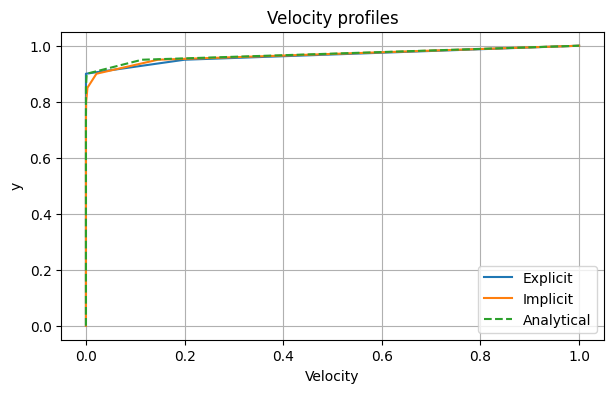

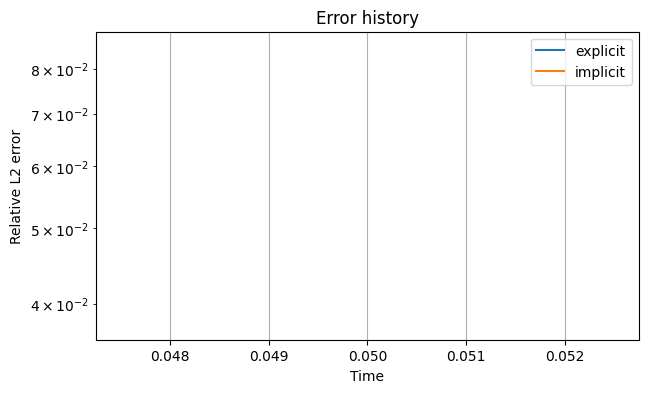

In [ ]:
#@title 5. Plot the primary numerical results
profiles = read_csv(OUT / "couette_profiles.csv")
plt.figure(figsize=(7, 4))
plt.plot(profiles["explicit_velocity"], profiles["y"], label="Explicit")
plt.plot(profiles["implicit_velocity"], profiles["y"], label="Implicit")
plt.plot(profiles["analytical_velocity"], profiles["y"], "--", label="Analytical")
plt.xlabel("Velocity")
plt.ylabel("y")
plt.title("Velocity profiles")
plt.legend()
plt.grid(True)
plt.show()

history = read_csv(OUT / "couette_history.csv")
plt.figure(figsize=(7, 4))
for method in np.unique(history["method"]):
    mask = history["method"] == method
    plt.semilogy(history["time"][mask], history["relative_l2_error"][mask], label=str(method))
plt.xlabel("Time")
plt.ylabel("Relative L2 error")
plt.title("Error history")
plt.legend()
plt.grid(True)
plt.show()

## Inline field visualization

This preview removes the need for ParaView during the basic laboratory workflow. The VTK file is still included in the downloaded results for optional advanced post-processing.

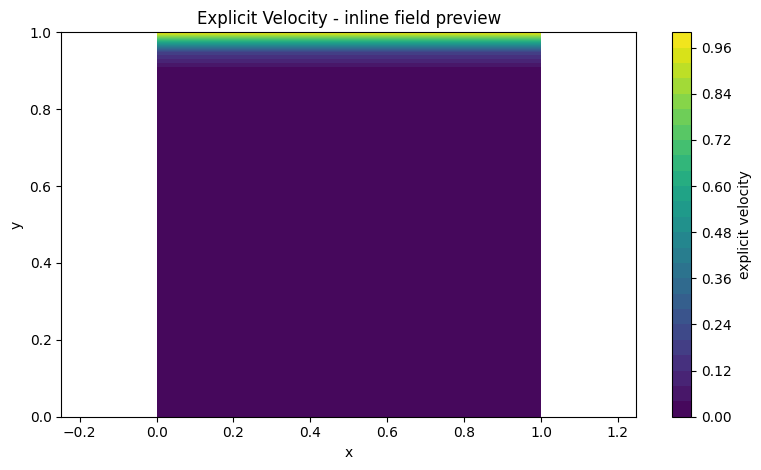

### Generated files
| File | Size |
|---|---:|
| `couette_field.vtk` | 7.6 KB |
| `couette_history.csv` | 277 B |
| `couette_plates.vtk` | 262 B |
| `couette_profiles.csv` | 1.2 KB |
| `couette_summary.txt` | 469 B |
| `solver_stderr.log` | 0 B |
| `solver_stdout.log` | 220 B |

In [ ]:
#@title 6. Display the final field and generated files
plot_vtk_scalar(OUT / 'couette_field.vtk', 'explicit_velocity')
files = list_outputs(OUT)


## Download results

In [ ]:
#@title 7. Package and download the results
DOWNLOAD_RESULTS = True #@param {type:"boolean"}
RESULTS_ZIP = make_results_zip(OUT, 5)
if DOWNLOAD_RESULTS:
    if IN_COLAB:
        colab_files.download(str(RESULTS_ZIP))
    else:
        print("Local test mode. Archive retained at:", RESULTS_ZIP)
else:
    print("Set DOWNLOAD_RESULTS to True and run this cell when ready to download.")


Results archive: /content/cfd_lab_exp05/experiment_05_results.zip (2.9 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Compulsory assignment

Run $Fo_{explicit}=0.25,0.45,0.55$ and explain the stability boundary. Compare explicit and implicit error and computational effort at the same physical time.

## Report checklist

- State the governing equations and boundary conditions.
- Report the complete parameter set and grid.
- Include residual or error history.
- Include the required quantitative comparison.
- Include at least one correctly labelled inline field figure; VTK/ParaView figures are optional unless specifically assigned.
- Distinguish observed numerical behaviour from physical interpretation.
- State the limitations of the supplied teaching model.